In [1]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))

# My imports
from src.driver import AnalysisDriver
import src.branches as branches
from src.cuts import CutConfig, create_cut

/home/syebes/lambda-ana/data/df/test.df


# Load files

In [2]:
# POT taken from preselection stage

lambda_pot = 1.428596135616784e+23
aurora_pot = 5.401777280854836e+20

In [3]:
lambda_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/newChi2LambdaFransOutput.root"
aurora_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/devFransOutput.root"

frans_tdir = "FRANSProducer/fransTree"

In [4]:
lambda_tree = uproot.open(lambda_file)[frans_tdir]
aurora_tree = uproot.open(aurora_file)[frans_tdir]

In [5]:
max_entry = None
indices =['run_id', 'subrun_id', 'event_id', 'slice_id']

lambda_df = pd.DataFrame(lambda_tree.arrays(branches.frans, library="np", entry_stop=max_entry))
aurora_df = pd.DataFrame(aurora_tree.arrays(branches.frans, library="np", entry_stop=max_entry))

lambda_df.set_index(indices, inplace=True)
aurora_df.set_index(indices, inplace=True)

In [6]:
pot_3y = 7e20

lambda_scale = pot_3y / lambda_pot
aurora_scale = pot_3y / aurora_pot

aurora_sgnl_mask = (aurora_df.n_lambda > 0) | (aurora_df.n_sigma0 > 0)

lambda_df['scale'] = pot_3y / (lambda_pot + aurora_pot)
aurora_df['scale'] = aurora_scale
aurora_df.loc[aurora_sgnl_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot)

In [7]:
df = pd.concat([lambda_df, aurora_df])

# Preselection

In [8]:
preselected_mask = df.pre_pass

pre_df = df[preselected_mask]

# Selection

import importlib
import src

importlib.reload(src.driver)
importlib.reload(src.plotter)
importlib.reload(src.frans_branches)
importlib.reload(src.cuts)
from src.driver import AnalysisDriver
from src.frans_branches import branches
from src.cuts import CutConfig, create_cut

In [9]:
import yaml

with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)

In [10]:
cuts_config = []

for cut_cfg in config['frans_cuts_no_michel'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    cuts_config.append(cfg)

In [11]:
driver = AnalysisDriver(pre_df, cuts_config)

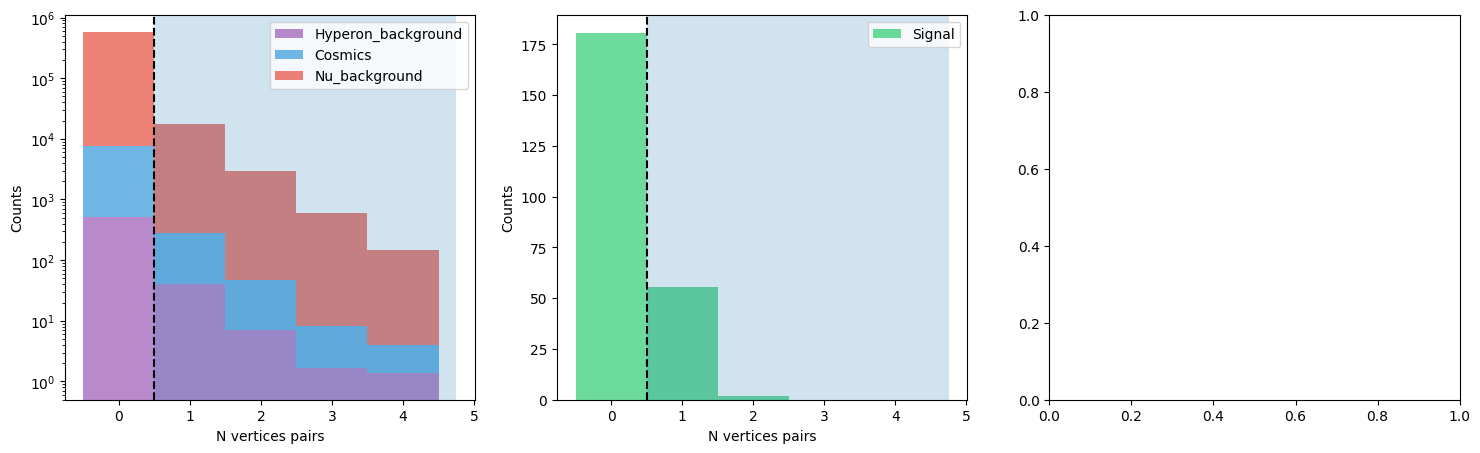

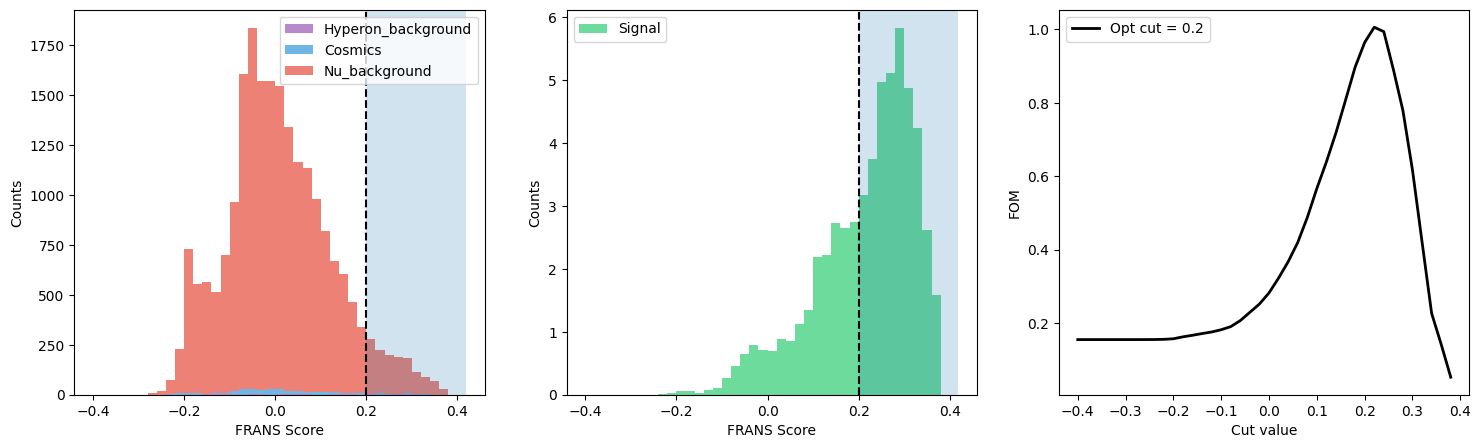

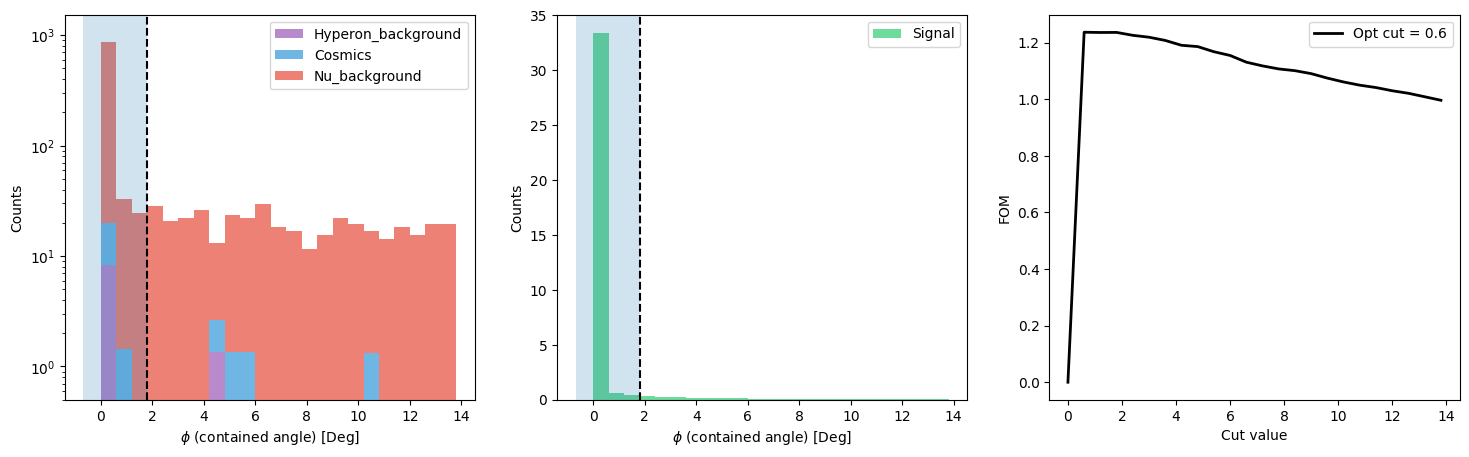

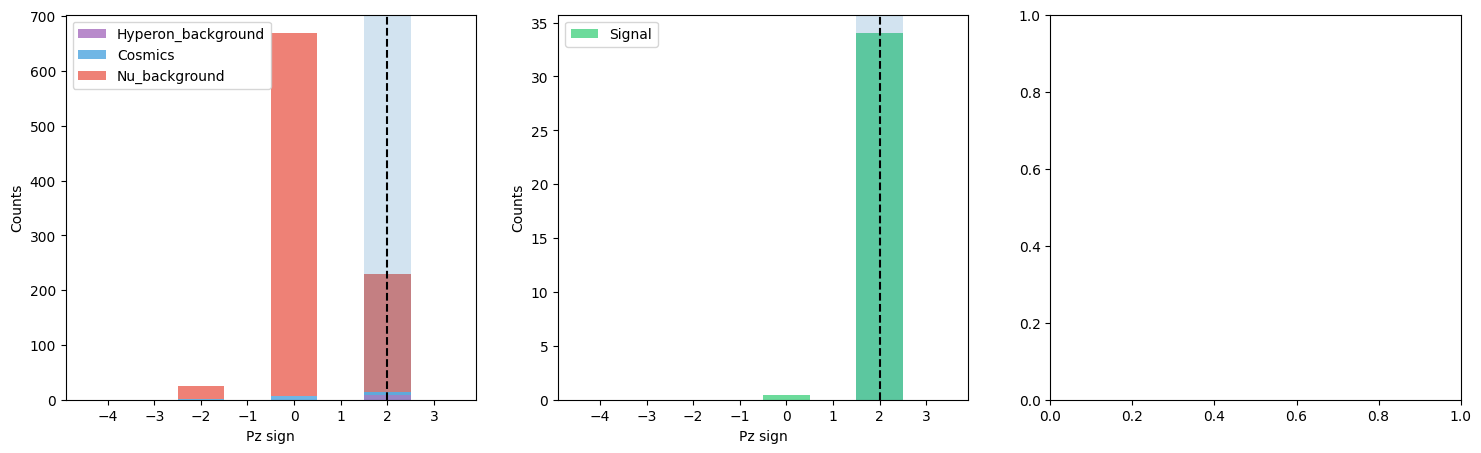

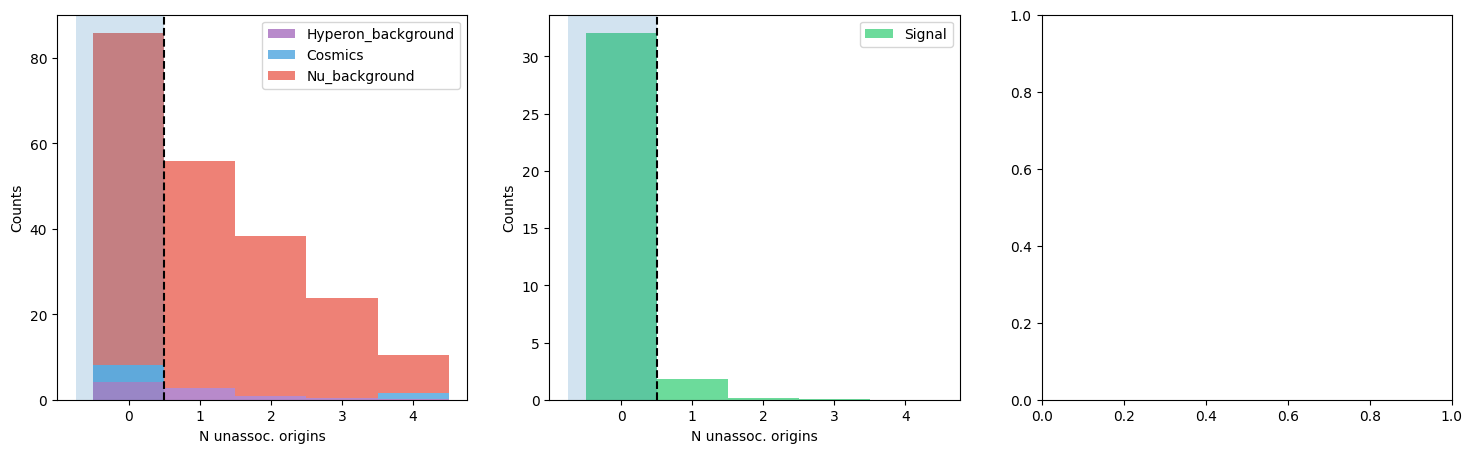

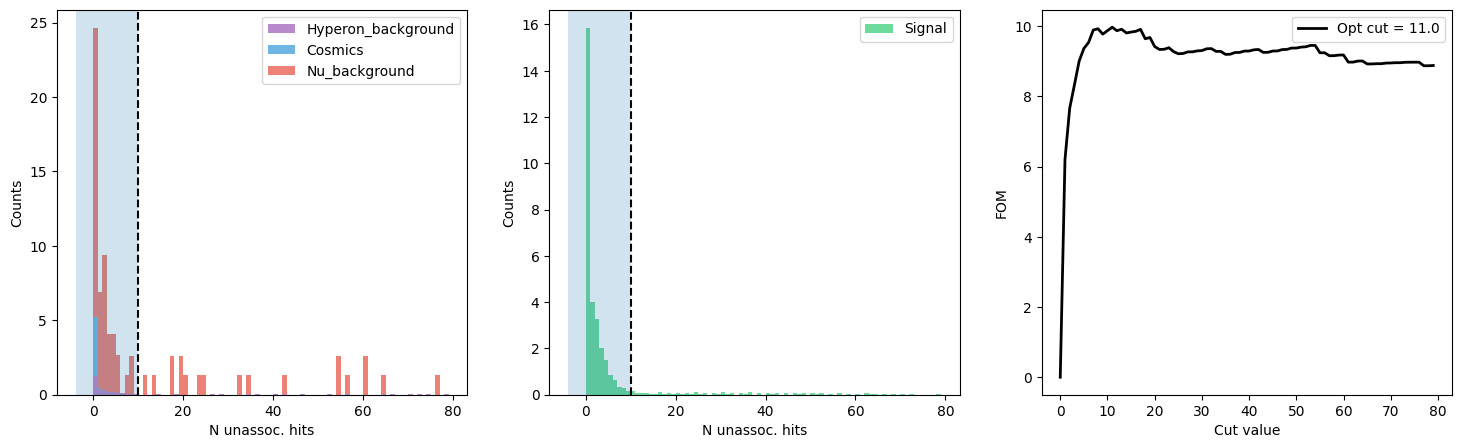

,Stage,Cut value,Signal,Hyperon_background,Cosmics,Nu_background,Cut efficiency (%),Total efficiency (%),Purity (%),Cut bck rejection (%),Total bck rejection (%)
0,N vertices pairs,>= 1,57.6,49.9,293.2,2.1e+04,24.20,24.20,0.27,96.46,96.4567
1,FRANS Score,> 0.2,37.0,10.9,18.3,1.4e+03,64.13,15.52,2.61,93.54,99.7712
2,$\phi$ (contained angle) [Deg],< 1.8,34.4,8.6,13.1,903.2,93.15,14.46,3.59,32.96,99.8466
3,Pz sign,== 2,34.0,8.2,5.3,216.4,98.82,14.29,12.89,75.14,99.9619
4,N unassoc. origins,< 1,32.0,4.1,4.0,77.8,94.18,13.46,27.19,62.68,99.9858
5,N unassoc. hits,< 10,28.9,2.6,4.0,49.2,90.30,12.15,34.12,34.90,99.9907


In [12]:
driver.plot_cuts()
driver.get_cuts_performance()

In [13]:
final_df = driver.get_final_df()

# Load FRANS PID tree

In [14]:
pid_tdir = "lambdaPidPandoraAna/CalorimetryTree"

lambda_pid_tree = uproot.open(lambda_file)[pid_tdir]
aurora_pid_tree = uproot.open(aurora_file)[pid_tdir]

In [15]:
lambda_pid_df = pd.DataFrame(lambda_pid_tree.arrays(branches.frans_pid, library="np", entry_stop=max_entry))
aurora_pid_df = pd.DataFrame(aurora_pid_tree.arrays(branches.frans_pid, library="np", entry_stop=max_entry))

In [16]:
pid_df = pd.concat([lambda_pid_df, aurora_pid_df])

In [17]:
pid_df.set_index(['RunID', 'SubRunID', 'EventID'], inplace=True)

In [18]:
final_df.index = final_df.index.droplevel(-1)
selected_indices = final_df.index

In [19]:
pid_df = pid_df[pid_df.index.isin(selected_indices)]

In [20]:
cols = ['is_lambda_signal', 'scale', 'gen_index', 'n_hyperon']

pid_df[cols] = final_df.loc[selected_indices, cols].values

In [21]:
pid_df['pid_cut'] = (pid_df.NTracksHI >=1) & (pid_df.NTracksLI >=1)

In [22]:
import yaml

with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)

In [23]:
pid_cuts_config = []

for cut_cfg in config['pid_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    pid_cuts_config.append(cfg)

In [24]:
pid_driver = AnalysisDriver(pid_df, pid_cuts_config)

/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/matplotlib/axes/_axes.py:7132: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  m, bins = np.histogram(x[i], bins, weights=w[i], **hist_kwargs)
/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/matplotlib/axes/_axes.py:7117: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  bins = np.histogram_bin_edges(


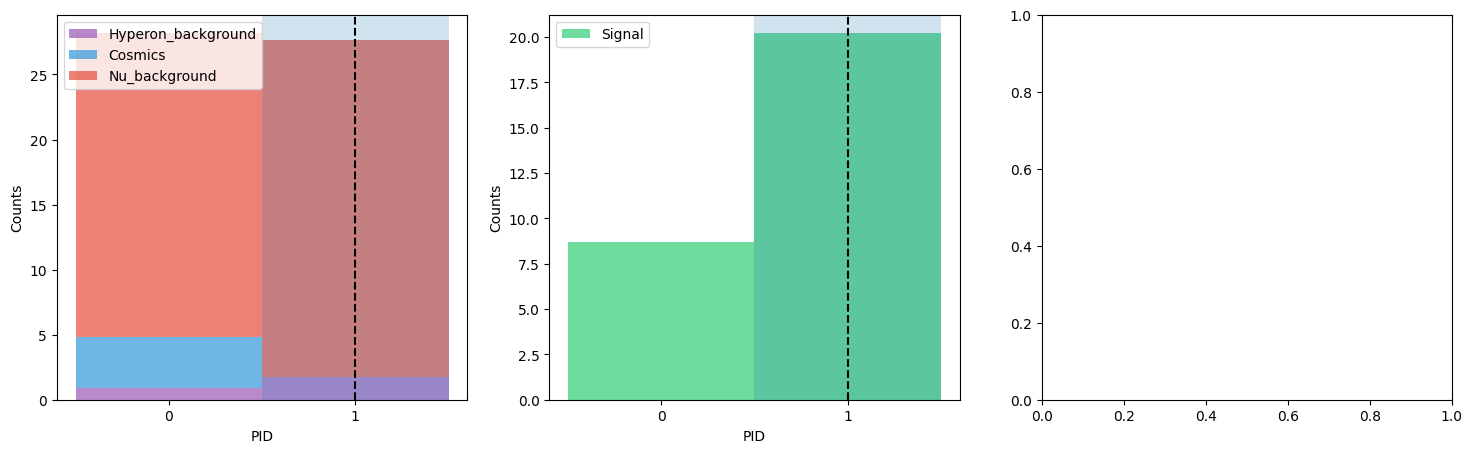

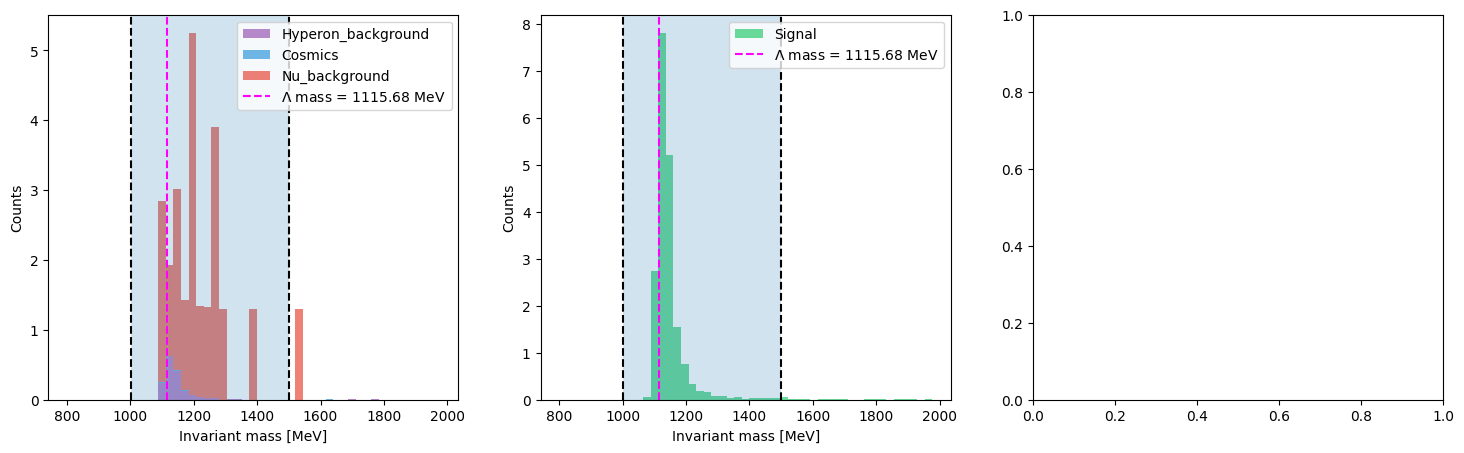

,Stage,Cut value,Signal,Hyperon_background,Cosmics,Nu_background,Cut efficiency (%),Total efficiency (%),Purity (%),Cut bck rejection (%),Total bck rejection (%)
0,PID,== 1,20.2,1.7,0.0,25.9,69.89,4.85,42.21,50.45,99.9999
1,Invariant mass [MeV],"[1000, 1499]",19.2,1.6,0.0,22.0,94.91,4.60,44.80,14.57,99.9999


In [25]:
pid_driver.plot_cuts()
pid_driver.get_cuts_performance(**config['initial_amounts'])